In [1]:
from pathlib import Path
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




def find_project_root(start: Path) -> Path:
    current = start.resolve()
    while current != current.parent:
        if (current / "src").exists():
            return current
        current = current.parent
    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())
os.chdir(PROJECT_ROOT)

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CWD:", Path.cwd())
print("ARTIFACTS:", ARTIFACTS)

PROJECT_ROOT: .
CWD: .
ARTIFACTS: ./artifacts


In [2]:
from ips_learning.visualization.utils import FigureRepository, TableRepository
figure_repo = FigureRepository(root_dir=ARTIFACTS)
table_repo = TableRepository(root_dir=ARTIFACTS)

In [3]:
SYSTEM_NAME = "kuramoto"
PROFILE_NAME = "profile1"
SYSTEM_ORDER = 1
INTERACTION_TYPE = "energy"
ENVIRONMENT_VARIABLE = "position"

# Stage 2.2b: Support and density diagnostics

In [4]:
TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

KDE_SPLIT = "kde"
KDE_DATASET_NAME = "dataset_kde"

FIGURE_STAGE = "step_2_2b"

In [5]:
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.features.feature_repository import FeatureRepository
from ips_learning.bases.repository import BasisRepository

from ips_learning.statistics.density import build_empirical_error_density

from ips_learning.statistics.density_repository import DensityRepository
from ips_learning.visualization.data_support import DataSupportVisualizer

In [6]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")
feature_repo = FeatureRepository(root_dir=ARTIFACTS / "features")
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")
density_repo = DensityRepository(root=ARTIFACTS / "densities")

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

features = feature_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    feature_name=TRAIN_FIT_DATASET_NAME,
)

basis_bundle = basis_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    basis_name=TRAIN_FIT_DATASET_NAME,
)

kernel_density_ref, env_density_ref = density_repo.load(
    system_name=SYSTEM_NAME,
    split=KDE_SPLIT,
    name=KDE_DATASET_NAME,
)

print("Loaded dataset/features/basis.")
print("X:", train_fit_dataset.X.shape)
print("V:", None if train_fit_dataset.V is None else train_fit_dataset.V.shape)
print("R:", features.R.shape)
print("Basis localization:", basis_bundle.localization_metadata)

Loaded dataset/features/basis.
X: (20, 51, 10, 1)
V: None
R: (20, 51, 10, 10, 1)
Basis localization: {'basis_stage': '2.2', 'env_max': [6.587611338766145], 'env_min': [-0.2545992313680897], 'environment_degree': 1, 'environment_family': 'bspline', 'environment_knots': [[-0.2545992313680897, -0.2545992313680897, 0.5056463875357141, 1.2658920064395178, 2.0261376253433214, 2.7863832442471255, 3.5466288631509295, 4.306874482054733, 5.067120100958537, 5.827365719862341, 6.587611338766145, 6.587611338766145]], 'environment_variable': 'position', 'interaction_type': 'energy', 'n_environment_basis_per_dim': 10, 'n_parametric_f_terms': 1, 'n_radial_basis': 10, 'parametric_f_terms': ['x'], 'r_max': 5.924811692298908, 'r_min': 0.0, 'radial_degree': 1, 'radial_family': 'bspline', 'radial_knots': [0.0, 0.0, 0.6583124102554342, 1.3166248205108684, 1.9749372307663027, 2.6332496410217368, 3.291562051277171, 3.9498744615326054, 4.608186871788039, 5.2664992820434735, 5.924811692298908, 5.924811692298908

In [ ]:
# Canonical empirical training density and evaluation grids.
#
# The M_rho=2000 reference KDE remains a separate object; both reference
# and empirical densities are evaluated on these same grids.
empirical_density = build_empirical_error_density(
    features=features,
    localization_metadata=basis_bundle.localization_metadata,
)

r_grid = empirical_density.r_grid
z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid

train_density = empirical_density.kernel_weights

if z2_grid is None:
    train_density_grid = empirical_density.environment_weights
else:
    train_density_grid = empirical_density.environment_weights.reshape(
        len(z1_grid),
        len(z2_grid),
    )


In [ ]:
# Pairwise-distance support:
# evaluate the M_rho=2000 reference KDE on the same canonical grid
# used for the empirical training density.
reference_pdf = kernel_density_ref.evaluate(r_grid)

viz = DataSupportVisualizer()

fig = viz.plot_pairwise_distance_support(
    basis_bundle=basis_bundle,
    r_grid=r_grid,
    reference_pdf=reference_pdf,
    train_density=train_density,
    title=None,
    reference_label=rf"$\rho_{{\Delta \theta}}$",
    train_label=rf"$\hat{{\rho}}_{{\Delta \theta}}$",
    xlabel=r"$\Delta \theta$",
    ylabel=rf"$\rho_{{d \theta}}$",
)


In [9]:
figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "pairwise_distance_support.png"
pdf_path = figure_dir / "pairwise_distance_support.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
./artifacts/kuramoto/figures/step_2_2b/pairwise_distance_support.png
./artifacts/kuramoto/figures/step_2_2b/pairwise_distance_support.pdf


In [ ]:
# Environment support metadata.
loc = basis_bundle.localization_metadata

env_min = np.asarray(
    loc.get("env_min", loc.get("v_min")),
    dtype=float,
)
env_max = np.asarray(
    loc.get("env_max", loc.get("v_max")),
    dtype=float,
)

environment_variable = loc.get(
    "environment_variable",
    "position" if SYSTEM_ORDER == 1 else "velocity",
)

print("environment_variable:", environment_variable)
print("env_min:", env_min)
print("env_max:", env_max)
print("z1_grid:", z1_grid.shape)
print("z2_grid:", None if z2_grid is None else z2_grid.shape)


In [ ]:
# Evaluate the M_rho=2000 reference environment KDE on the same
# canonical grid used for the empirical training density.
if z2_grid is None:
    density_grid = env_density_ref.evaluate(z1_grid)
else:
    density_grid = env_density_ref.evaluate_on_grid(
        z1_grid,
        z2_grid,
    )


In [ ]:
# The empirical training environment density was built directly
# from the current training features in cell 7.
#
# train_density_grid is intentionally kept separate from density_grid:
#   density_grid       -> M_rho=2000 reference KDE
#   train_density_grid -> empirical training measure


Saved:
./artifacts/kuramoto/figures/step_2_2b/environment_support_density.png
./artifacts/kuramoto/figures/step_2_2b/environment_support_density.pdf


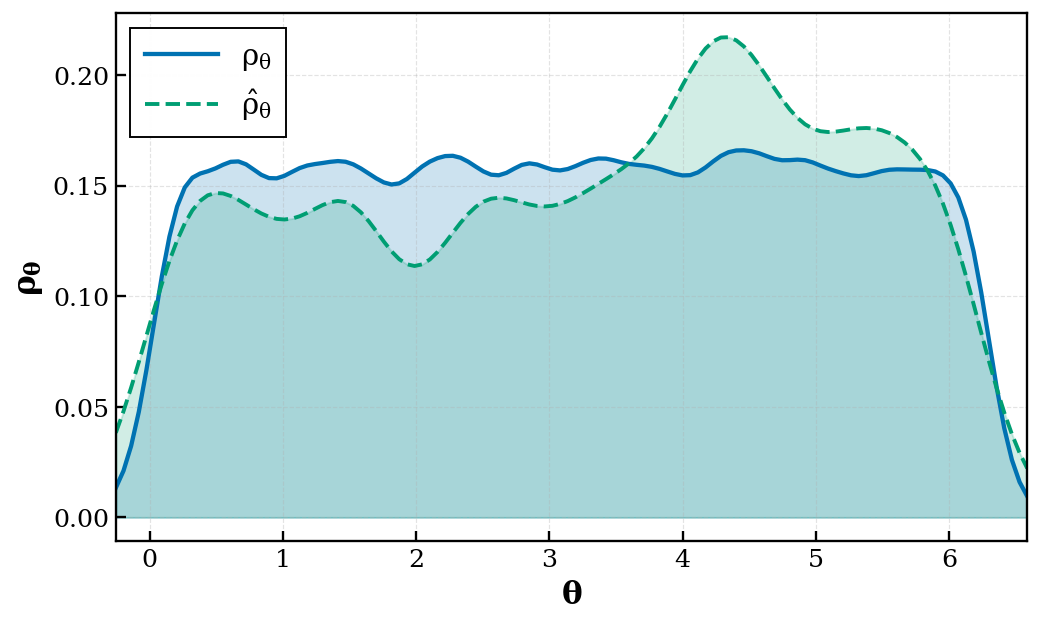

In [13]:
fig_env = viz.plot_environment_support_density(
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    density_grid=density_grid,
    empirical_density_grid =train_density_grid,
    title=None,
    density_label=rf"$\rho_{{\theta}}$",
    empirical_density_label=rf"$\hat{{\rho}}_{{\theta}}$",
    z_label=r"$\theta$",#r"$x$" if SYSTEM_ORDER == 1 else r"$v$",
    ylabel = rf"$\rho_{{\theta}}$",
)

figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "environment_support_density.png"
pdf_path = figure_dir / "environment_support_density.pdf"

fig_env.savefig(png_path, dpi=300, bbox_inches="tight")
fig_env.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

In [14]:
# Basis localization summary table
loc = basis_bundle.localization_metadata

env_min = np.asarray(loc.get("env_min", loc.get("v_min")), dtype=float)
env_max = np.asarray(loc.get("env_max", loc.get("v_max")), dtype=float)

row = {
    "system_name": SYSTEM_NAME,
    "profile_name": PROFILE_NAME,
    "dataset_name": TRAIN_FIT_DATASET_NAME,
    "system_order": SYSTEM_ORDER,
    "environment_variable": loc.get("environment_variable", ENVIRONMENT_VARIABLE),

    "radial_family": loc["radial_family"],
    "radial_degree": loc["radial_degree"],
    "n_radial_basis": basis_bundle.radial_basis.n_basis,

    "environment_family": loc.get("environment_family", loc.get("velocity_family")),
    "environment_degree": loc.get("environment_degree", loc.get("velocity_degree")),
    "environment_n_basis_per_dim": basis_bundle.environment_basis.n_basis_per_dim,

    "r_min": float(loc["r_min"]),
    "r_max": float(loc["r_max"]),
}

for d in range(env_min.shape[0]):
    row[f"z{d+1}_min"] = float(env_min[d])
    row[f"z{d+1}_max"] = float(env_max[d])

basis_localization_summary = pd.DataFrame([row])
basis_localization_summary

table_dir = table_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
table_dir.mkdir(parents=True, exist_ok=True)

csv_path = table_dir / "basis_localization_summary.csv"
tex_path = table_dir / "basis_localization_summary.tex"

basis_localization_summary.to_csv(csv_path, index=False)
basis_localization_summary.to_latex(
    tex_path,
    index=False,
    float_format="%.4e",
)

print("Saved:")
print(csv_path)
print(tex_path)

Saved:
./artifacts/kuramoto/tables/step_2_2b/basis_localization_summary.csv
./artifacts/kuramoto/tables/step_2_2b/basis_localization_summary.tex


In [15]:
basis_localization_summary

,system_name,profile_name,dataset_name,system_order,environment_variable,radial_family,radial_degree,n_radial_basis,environment_family,environment_degree,environment_n_basis_per_dim,r_min,r_max,z1_min,z1_max
0,kuramoto,profile1,dataset_train_fit_trial_001,1,position,bspline,1,10,bspline,1,10,0.0,5.924812,-0.254599,6.587611


Saved:
./artifacts/kuramoto/figures/step_2_2b/radial_basis_support.png
./artifacts/kuramoto/figures/step_2_2b/radial_basis_support.pdf


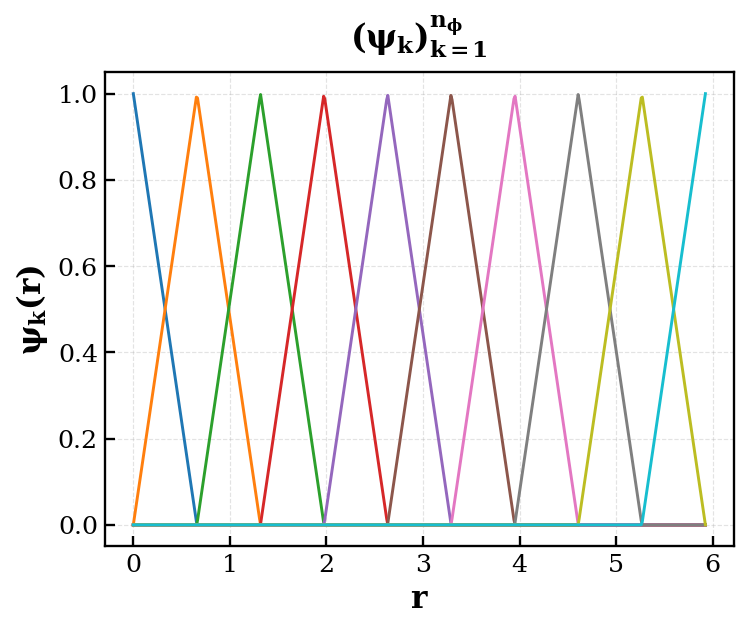

In [16]:
# Radial basis support plot

viz = DataSupportVisualizer()


fig_radial_basis = viz.plot_radial_basis_support(
    basis_bundle=basis_bundle,
)

fig_radial_basis


figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "radial_basis_support.png"
pdf_path = figure_dir / "radial_basis_support.pdf"

fig_radial_basis.savefig(png_path, dpi=300, bbox_inches="tight")
fig_radial_basis.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
./artifacts/kuramoto/figures/step_2_2b/environment_basis_support.png
./artifacts/kuramoto/figures/step_2_2b/environment_basis_support.pdf


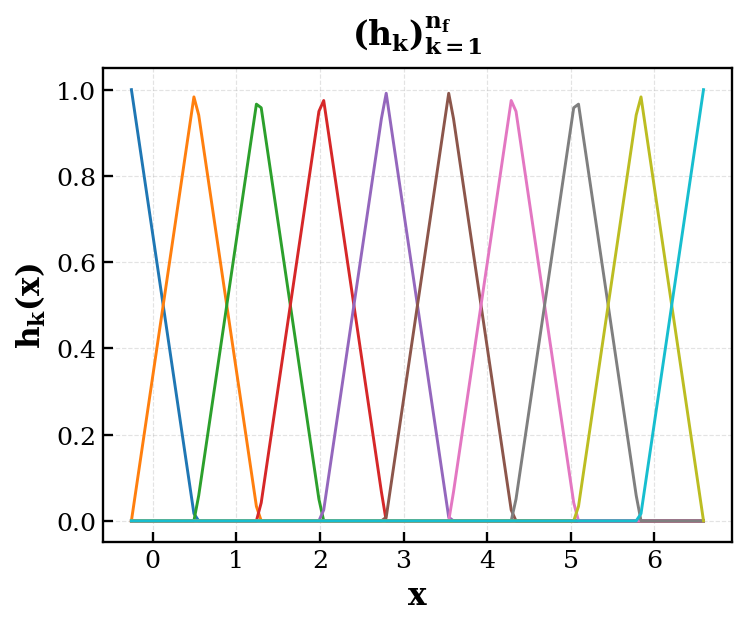

In [17]:
# Velocity basis support plot
fig_environment_basis = viz.plot_environment_basis_support(
    basis_bundle=basis_bundle,
    variable_label="x" if SYSTEM_ORDER == 1 else "v",
)

png_path = figure_dir / "environment_basis_support.png"
pdf_path = figure_dir / "environment_basis_support.pdf"

fig_environment_basis.savefig(png_path, dpi=300, bbox_inches="tight")
fig_environment_basis.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

# Stage 4b: Learned function visualizations

reference distance density \(\rho_R(r)\), environment density \(\rho_Z(z)\)

where \(z=v\) for second-order systems and \(z=x\) for first-order systems.

In [18]:
FIGURE_STAGE = "step_4b"
FIT_CASE_NAME = TRAIN_FIT_DATASET_NAME

In [19]:
from ips_learning.systems.registry import (
    true_env_from_metadata,
    true_kernel_from_metadata)

true_phi = true_kernel_from_metadata(train_fit_dataset.metadata)
true_f = true_env_from_metadata(train_fit_dataset.metadata)


In [20]:
from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
# loading fit repo
fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

fit_result = fit_repo.load_fit_result(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    fit_case_name=FIT_CASE_NAME,
)
learned_model = LearnedModelFactory().build_from_fit_result(
    fit_result=fit_result,
    N=int(fit_result.metadata["N"]),
    D=int(fit_result.metadata["D"]),
)

print("Learned model reconstructed.")
print("interaction_type:", learned_model.interaction_type)

Learned model reconstructed.
interaction_type: energy


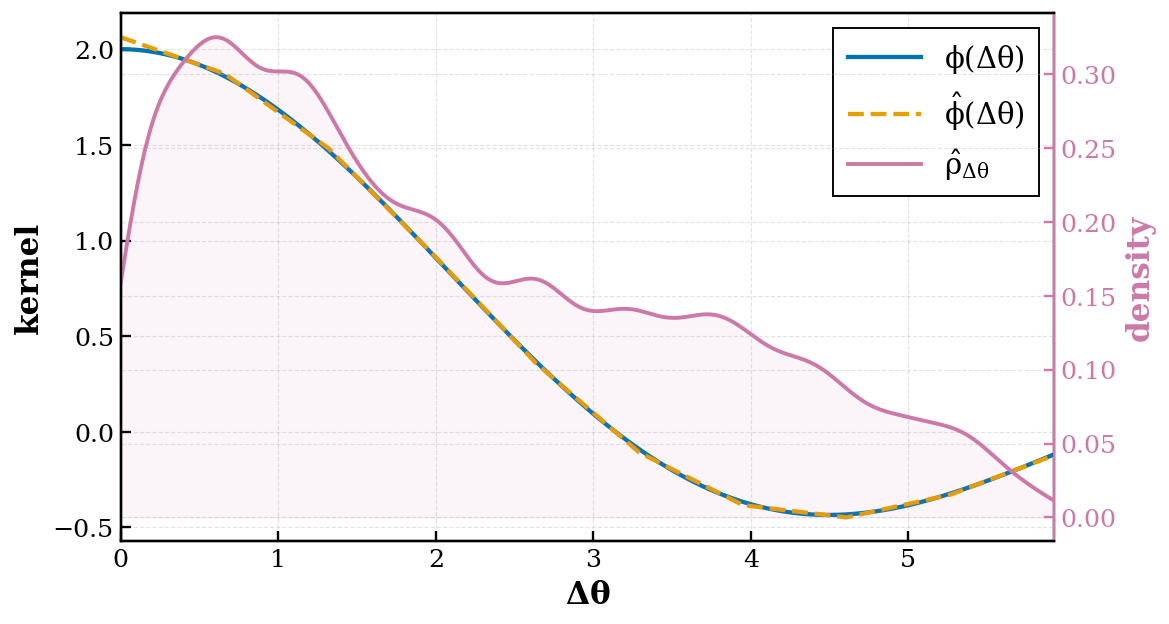

In [21]:
from ips_learning.visualization.learned_functions import LearnedFunctionVisualizer
viz = LearnedFunctionVisualizer()

fig_kernel = viz.plot_kernel_with_support(
    learned_model=learned_model,
    basis_bundle=basis_bundle,
    r_grid=r_grid,
    true_kernel=true_phi,
    train_density= train_density,
    labels={
        "true_kernel_label": r"${\phi}(\Delta \theta)$",
        "learned_kernel_label": r"$\hat{\phi}(\Delta \theta)$",
        "train_density_label": r"$\hat{\rho}_{\Delta \theta}$",
        "xlabel": r"$\Delta \theta$",
        "y1label": "kernel",#r"$\phi(\Delta \theta)$",
        "y2label": "density",#r"$\rho_{\Delta \theta}$",
        "legend_loc": "best",
        "legend_bbox_to_anchor": None,
    },
)

#change label

figure_repo.save(
    fig_kernel,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_kernel_phi",
)
fig_kernel

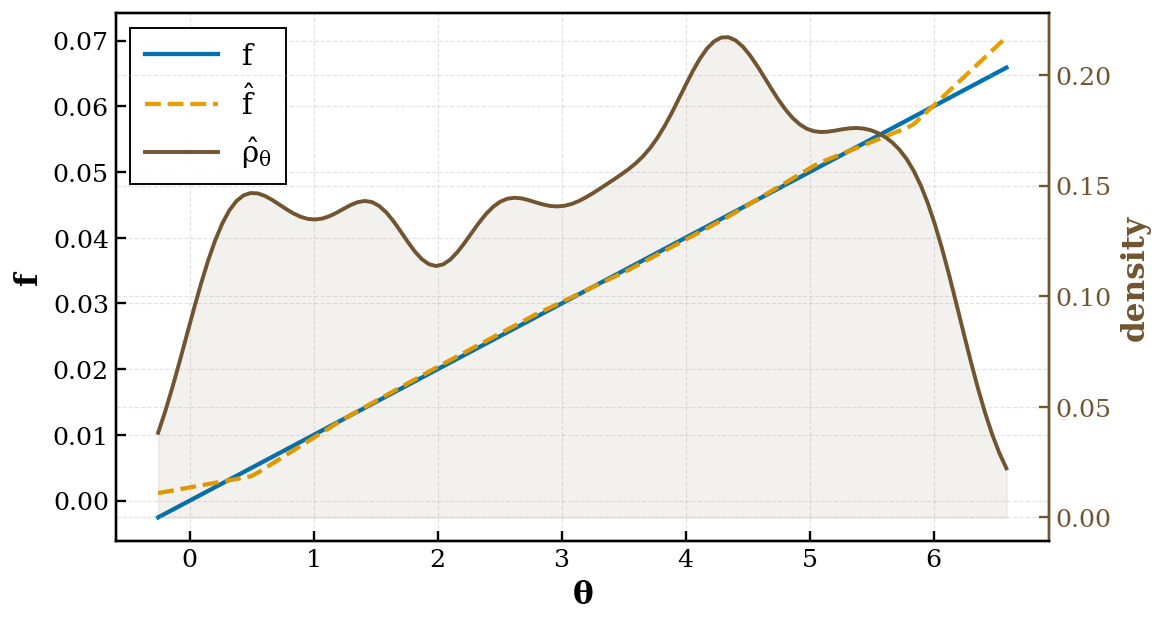

In [22]:
fig_f = viz.plot_environment_with_support(
    learned_model=learned_model,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=train_density_grid,
    true_env=true_f,
    environment_variable=r"\theta",#x" if SYSTEM_ORDER == 1 else "v",
    labels={
        "xlabel": r"$\theta$",
        "y1label" : r"$f$",
        "density_ylabel":  "density",
        "true_label": r"$f$",
        "learned_label": r"$\hat f$",
        "density_label": r"$\hat{\rho}_{\theta}$",
    },
)
figure_repo.save(
    fig_f,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_f",
)
fig_f

#change to data distribution instesd of 

# Stage 4c: Algorithm comparison — learned functions

In [23]:
FIGURE_STAGE = "step_4c"
ALGORITHMS = ("nonparametric_f", "parametric_f")

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.visualization.algorithm_comparison import AlgorithmComparison

fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

FIT_RESULTS = {}
LEARNED_MODELS = {}

for algorithm in ALGORITHMS:
    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        fit_case_name=FIT_CASE_NAME,
    )

    learned_model = LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=int(fit_result.metadata["N"]),
        D=int(fit_result.metadata["D"]),
    )

    FIT_RESULTS[algorithm] = fit_result
    LEARNED_MODELS[algorithm] = learned_model

    print("Loaded:", algorithm, fit_result.theta.shape)

Loaded: nonparametric_f (20, 1)
Loaded: parametric_f (11, 1)


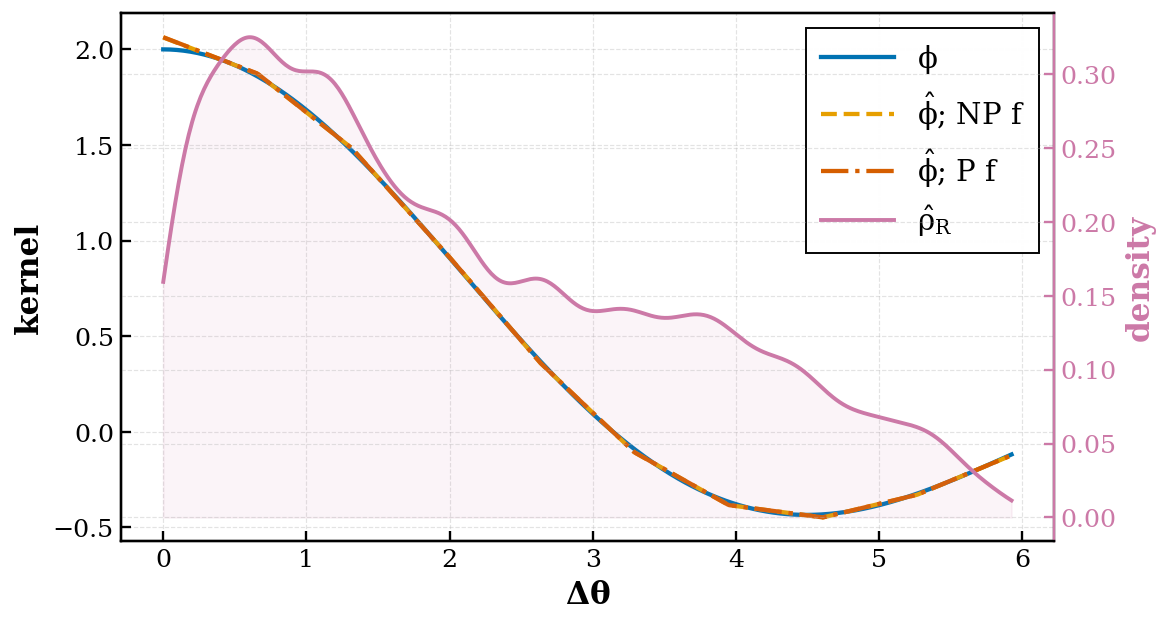

In [24]:
viz = AlgorithmComparison()

fig_kernel_compare = viz.plot_kernel_algorithm_comparison(
    r_grid=r_grid,
    true_kernel=true_phi,
    learned_models=LEARNED_MODELS,
    train_density=train_density,
    labels={
        "x_label": r"$\Delta \theta$",
        "y_label": "kernel",
        "y2_label": "density",
        "density_label": r"$\hat{\rho}_R$",
        "true_label": r"$\phi$",
        "learned_labels": {
            "nonparametric_f": r"$\hat{\phi}$; NP $f$",
            "parametric_f": r"$\hat{\phi}$; P $f$",
        },
        "legend_loc": "best",
    },
)
figure_repo.save(
    fig_kernel_compare,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_kernel_comparison",
)
fig_kernel_compare

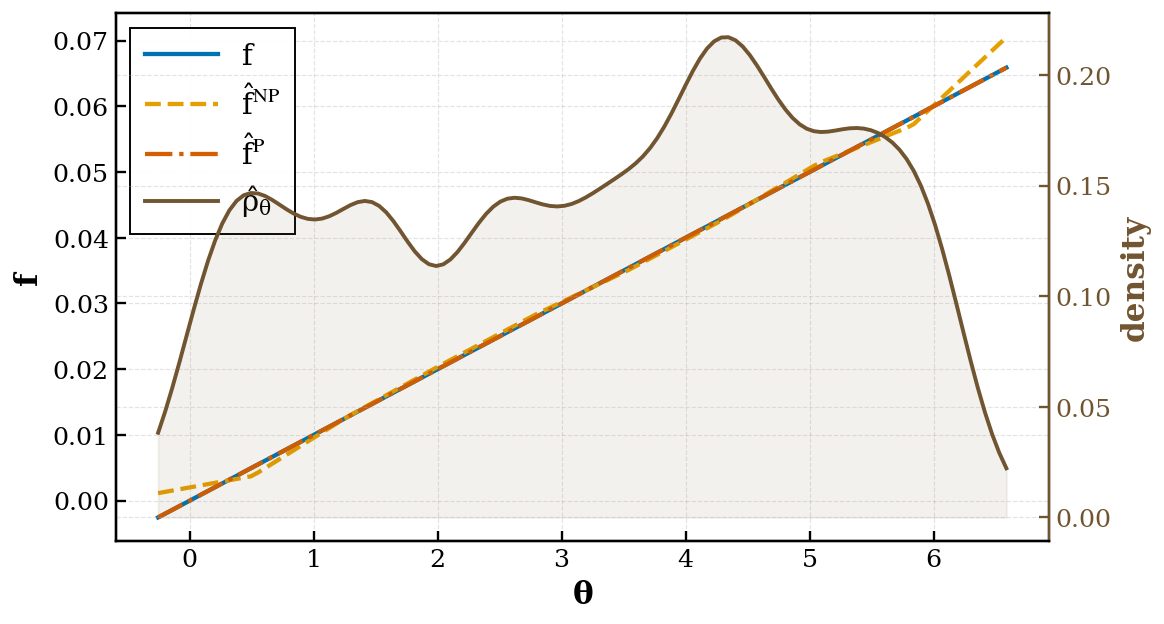

In [25]:
fig_f_compare_1d = viz.plot_environment_surfaces_1d(
    learned_models=LEARNED_MODELS,
    z_grid=z1_grid,
    reference_density=train_density_grid,
    true_env=true_f,
    environment_variable="x",
    labels={
        "xlabel": r"$\theta$",
        "ylabel": r"$f$",
        "true_label": r"$f$",
        "learned_labels": {
            "nonparametric_f": r"$\hat f^{\mathrm{NP}}$",
            "parametric_f":  r"$\hat f^{\mathrm{P}}$",
        },
        "density_label": r"$\hat{\rho}_{\theta}$",
        "density_ylabel": "density",#r"$\rho_x(x)$",
        "legend_loc": "best",
    },
)
figure_repo.save(
    fig_f_compare_1d,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_f_comparison_1d",
)
fig_f_compare_1d

# Stage 5b: Rollout visualizations — true vs learned trajectories

In [26]:
FIGURE_STAGE = "step_5b"
FIT_CASE_NAME = TRAIN_FIT_DATASET_NAME

ALGORITHMS = ("nonparametric_f", "parametric_f")

FIT_RECON_ROLLOUT_NAME = f"{FIT_CASE_NAME}_train_fit_reconstruction"
TRAIN_FULL_ROLLOUT_NAME = f"{FIT_CASE_NAME}_train_full_prediction"
TEST_ROLLOUT_NAME = f"{FIT_CASE_NAME}_test_prediction"

TRAIN_SPLIT = "train"
TEST_SPLIT = "test"

TRAIN_DATASET_NAME = "dataset_train_trial_001"
TEST_DATASET_NAME = "dataset_test"

FIT_END_TIME = 0.5

In [27]:
from ips_learning.rollout.repository import RolloutRepository

rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")
ROLLOUT_ARTIFACTS = {}

for algorithm in ALGORITHMS:
    train_full_artifact = rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        case_name=FIT_CASE_NAME,
        scenario="train_full_prediction",
        rollout_name=TRAIN_FULL_ROLLOUT_NAME,
    )

    test_artifact = rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        case_name=FIT_CASE_NAME,
        scenario="test_prediction",
        rollout_name=TEST_ROLLOUT_NAME,
    )

    ROLLOUT_ARTIFACTS[algorithm] = {
        "train_full_prediction": train_full_artifact,
        "test_prediction": test_artifact,
    }

    print("Loaded rollout artifacts:", algorithm)
    print("train full:", train_full_artifact.X_hat.shape)
    print("test:", test_artifact.X_hat.shape)

Loaded rollout artifacts: nonparametric_f
train full: (20, 201, 10, 1)
test: (10, 201, 10, 1)
Loaded rollout artifacts: parametric_f
train full: (20, 201, 10, 1)
test: (10, 201, 10, 1)


In [28]:
# true datasets

train_full_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

test_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

In [29]:
# Helper to extract one trajectory
def extract_single_trajectory(dataset, artifact, m: int = 0):
    """
    Convert saved layout:
        dataset.X[m]      : (L, N, D)
        artifact.X_hat[m] : (L, N, D)

    to visualization layout:
        X_true : (N, D, L)
        X_hat  : (N, D, L)

    V_true and V_hat are None for first-order systems.
    """
    t = dataset.t

    X_true = np.transpose(dataset.X[m], (1, 2, 0))
    X_hat = np.transpose(artifact.X_hat[m], (1, 2, 0))

    if dataset.V is None:
        V_true = None
    else:
        V_true = np.transpose(dataset.V[m], (1, 2, 0))

    if artifact.V_hat is None:
        V_hat = None
    else:
        V_hat = np.transpose(artifact.V_hat[m], (1, 2, 0))

    return t, X_true, V_true, X_hat, V_hat

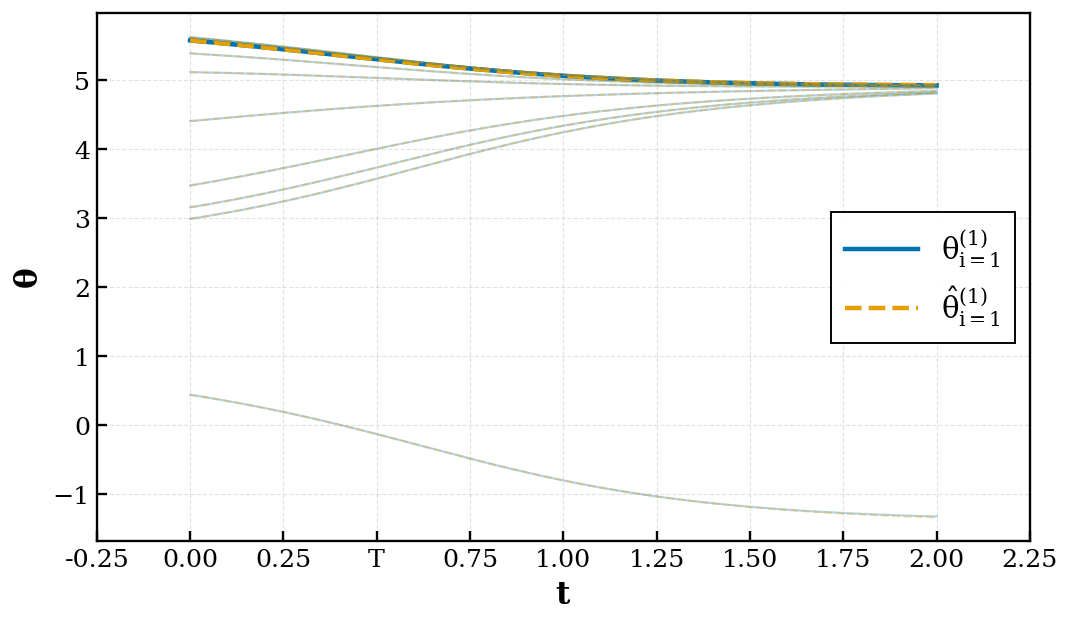

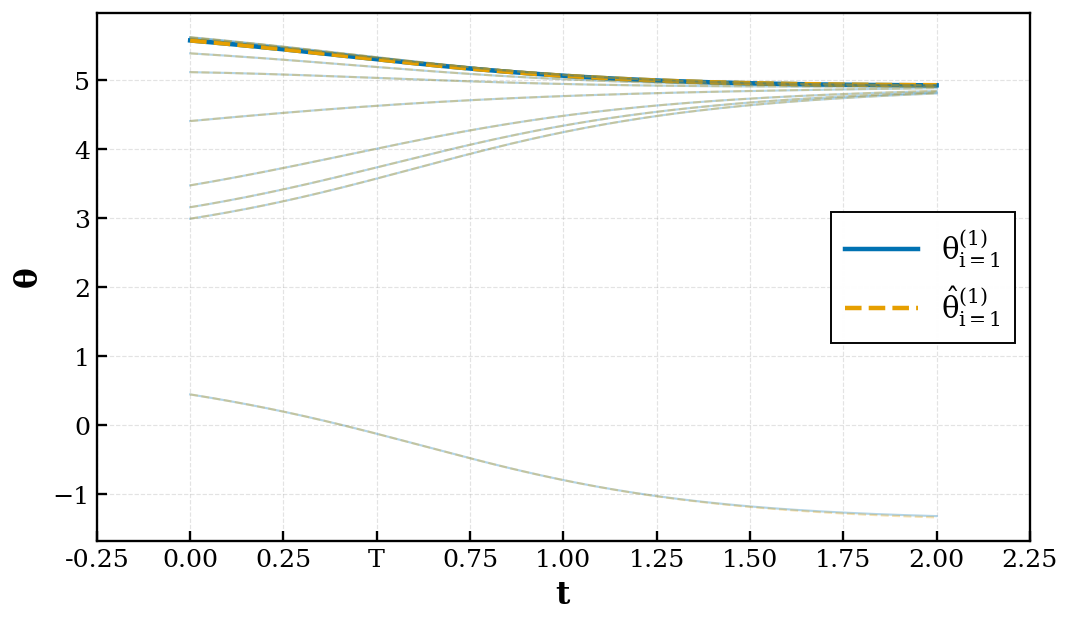

In [30]:
from ips_learning.visualization.trajectories import TrajectoryVisualizer

viz = TrajectoryVisualizer()

for algorithm in ALGORITHMS:
    train_full_artifact = ROLLOUT_ARTIFACTS[algorithm]["train_full_prediction"]

    t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
        train_full_dataset,
        train_full_artifact,
        m=0,
    )

    fig_coord_train = viz.plot_true_vs_learned_coordinate(
        t_true=t,
        X_true=X_true,
        t_hat=train_full_artifact.t,
        X_hat=X_hat,
        component=0,
        train_fit_end_pt=FIT_END_TIME,
        highlight_agent=0,
        title=None,#rf"$\theta_0 \in M_{{\mathrm{{train}}}},\ t \in [t_0,T_f]$ ",
        input_parameter=r"\theta"
    )

    figure_repo.save(
        fig_coord_train,
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"{algorithm}_train_full_coordinate",
        close=False,
    )

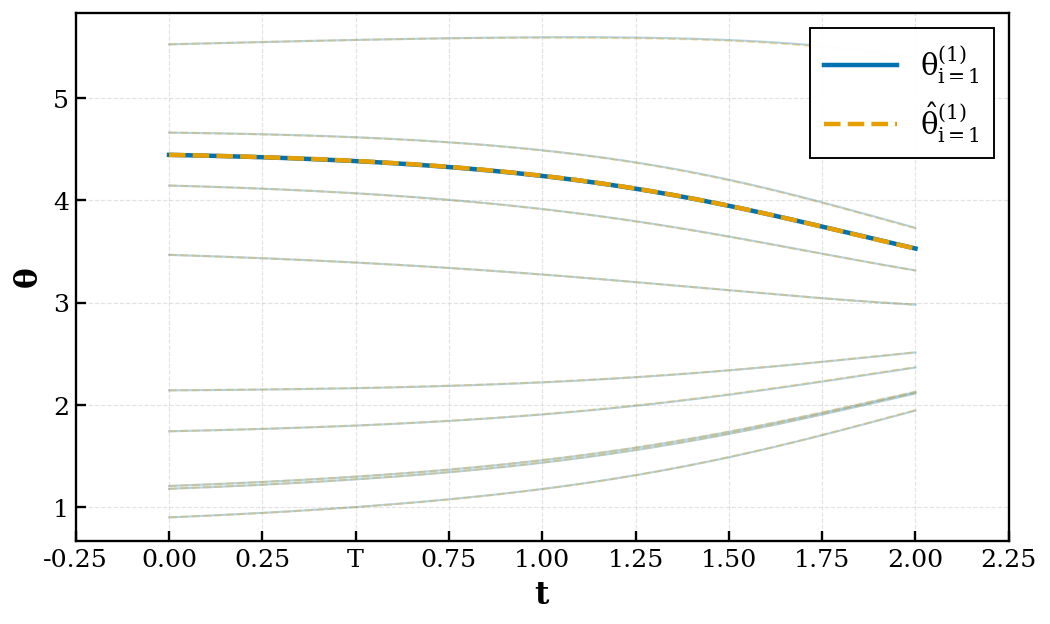

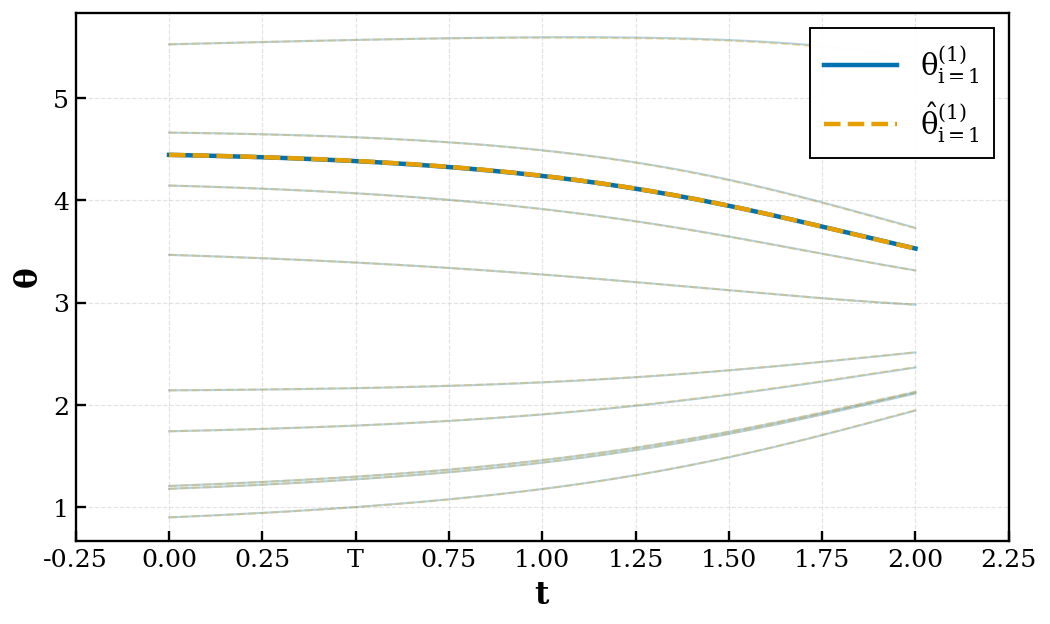

In [31]:
# unseen test prediction phase portrait
for algorithm in ALGORITHMS:
    train_full_artifact = ROLLOUT_ARTIFACTS[algorithm]["test_prediction"]

    t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
        test_dataset,
        test_artifact,
        m=0,
    )


    fig_coord_train = viz.plot_true_vs_learned_coordinate(
        t_true=t,
        X_true=X_true,
        t_hat=train_full_artifact.t,
        X_hat=X_hat,
        component=0,
        train_fit_end_pt=FIT_END_TIME,
        highlight_agent=0,
        title=None,#rf"$\theta_0 \in M_{{\mathrm{{test}}}},\ t \in [t_0,T_f]$ ",
        input_parameter=r"\theta"
    )

    figure_repo.save(
        fig_coord_train,
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"{algorithm}_test_full_coordinate",
        close=False,
    )